# Trabajo final · Alerta temprana de PM2.5 alto en Beijing

**Autora:** Kimberly Pereyra · INF-8239 Ciencia de Datos II · Modalidad A (proyecto aplicado)

- **Pregunta:** ¿Se puede anticipar con **12 horas** si la concentración de PM2.5 superará **75 µg/m³** (límite de 24 h de la norma china GB 3095-2012, grado II), usando solo la medición actual, sus valores pasados y la meteorología?
- **Datos:** *Beijing PM2.5* — UCI ML Repository, id 381 (Chen, 2015). DOI 10.24432/C5JS49. Licencia CC BY 4.0. Mediciones horarias de la Embajada de EE. UU. en Beijing (2010–2014) y meteorología del aeropuerto.
- **Partición temporal:** entrenamiento 2010–2012 · validación 2013 (selección de modelo y umbral) · prueba 2014 (evaluación final única).
- **Métrica principal:** F1 macro; además recall de la clase *alto* y ROC-AUC. Costo: tiempo de ajuste, inferencia y tamaño.

In [1]:
import json, runpy
import pandas as pd
from IPython.display import Image, display
from calidad_aire.config import RAW_CSV, REPORTS, ROOT

def run(name):
    runpy.run_path(str(ROOT / "scripts" / name), run_name="__main__")

if not RAW_CSV.exists():
    run("download_data.py")
print("Datos:", RAW_CSV.relative_to(ROOT))

Datos: data\raw\beijing_pm25.csv


## 1. Auditoría de los datos

{
  "rows": 43824,
  "start": "2010-01-01 00:00:00",
  "end": "2014-12-31 23:00:00",
  "missing_hours": 0,
  "duplicate_timestamps": 0,
  "nulls": {
    "pm25": 2067
  },
  "pm25_missing_pct": 4.72,
  "pm25_describe": {
    "count": 41757.0,
    "mean": 98.6,
    "std": 92.1,
    "min": 0.0,
    "25%": 29.0,
    "50%": 72.0,
    "75%": 137.0,
    "max": 994.0
  },
  "pct_hours_above_threshold": 48.5,
  "modeling_rows": {
    "train": 23871,
    "valid": 8605,
    "test": 8556
  },
  "high_rate": {
    "train": 0.486,
    "valid": 0.478,
    "test": 0.481
  },
  "missing_pm25_by_year": {
    "2010": 669,
    "2011": 728,
    "2012": 489,
    "2013": 82,
    "2014": 99
  }
}


Guardado: reports/audit.json y reports/audit_pm25.png


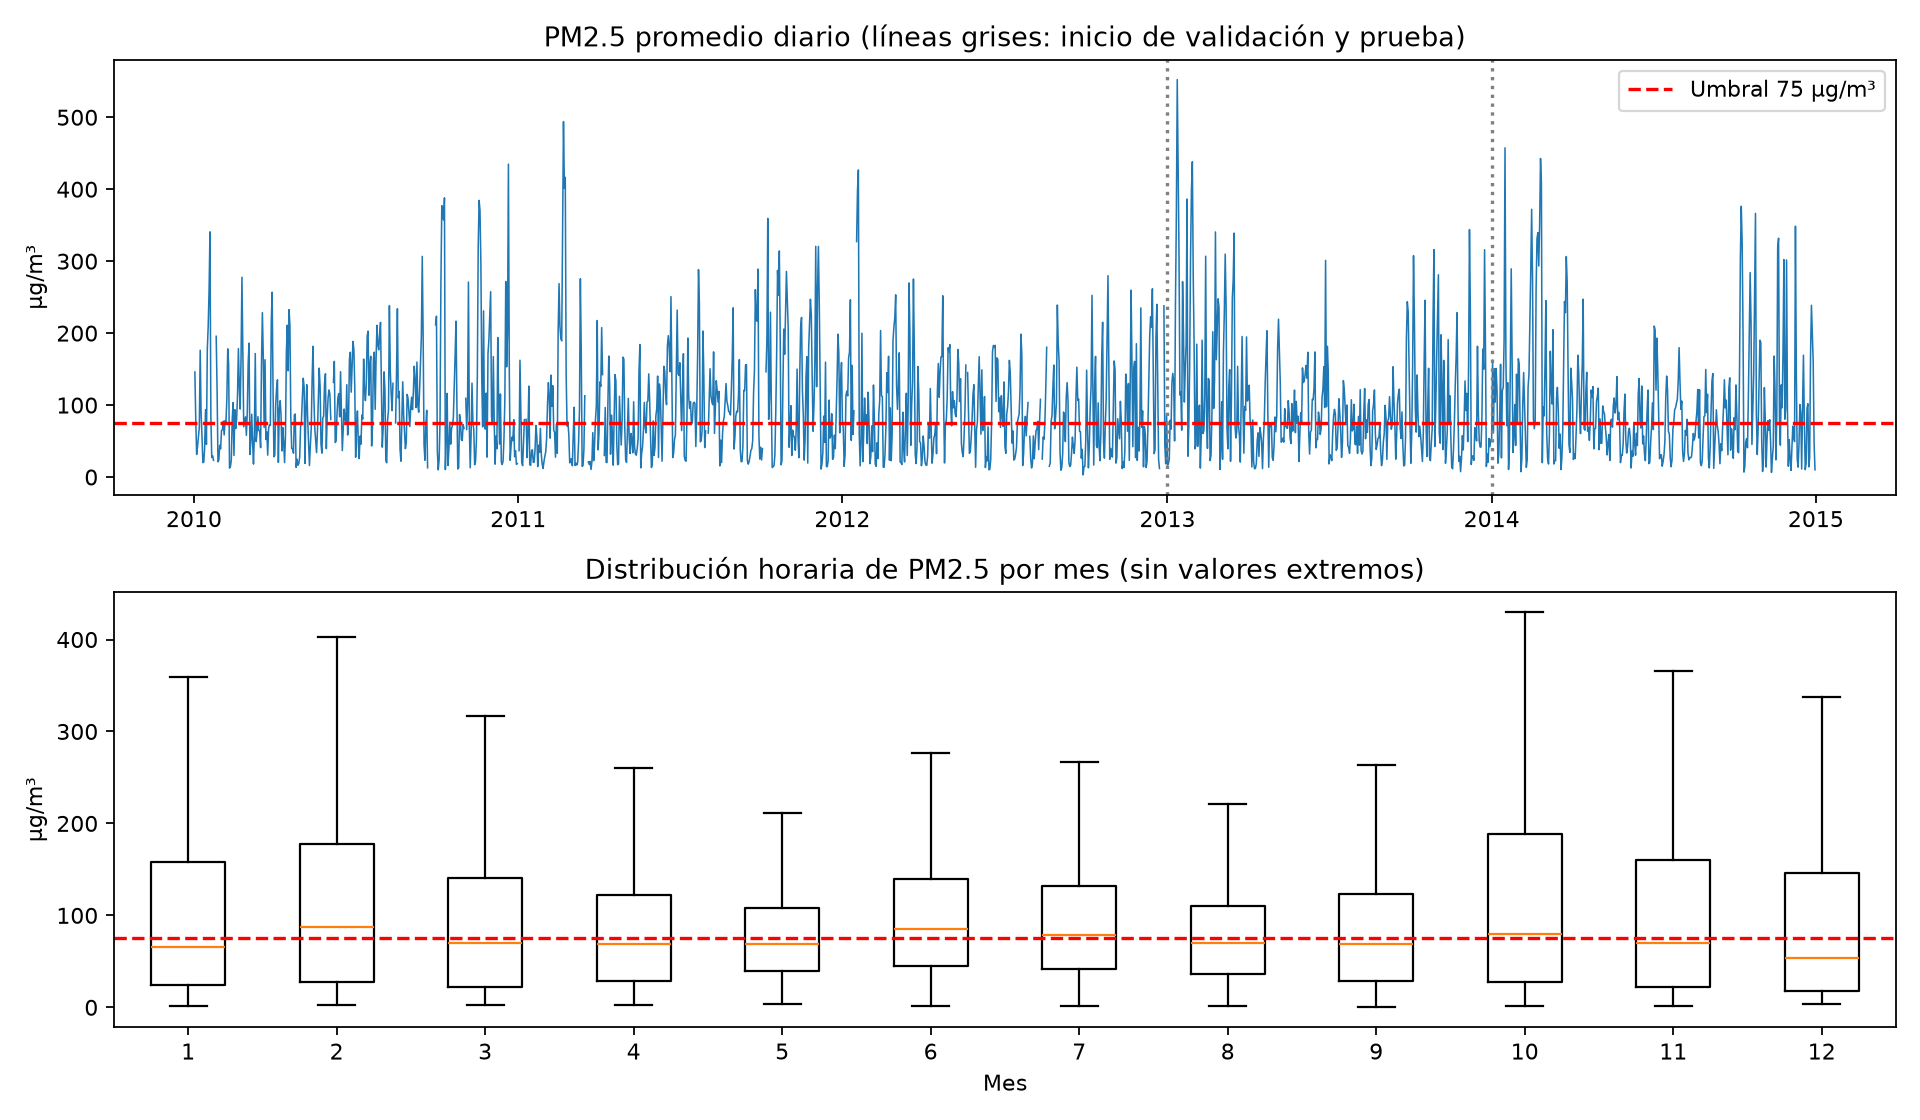

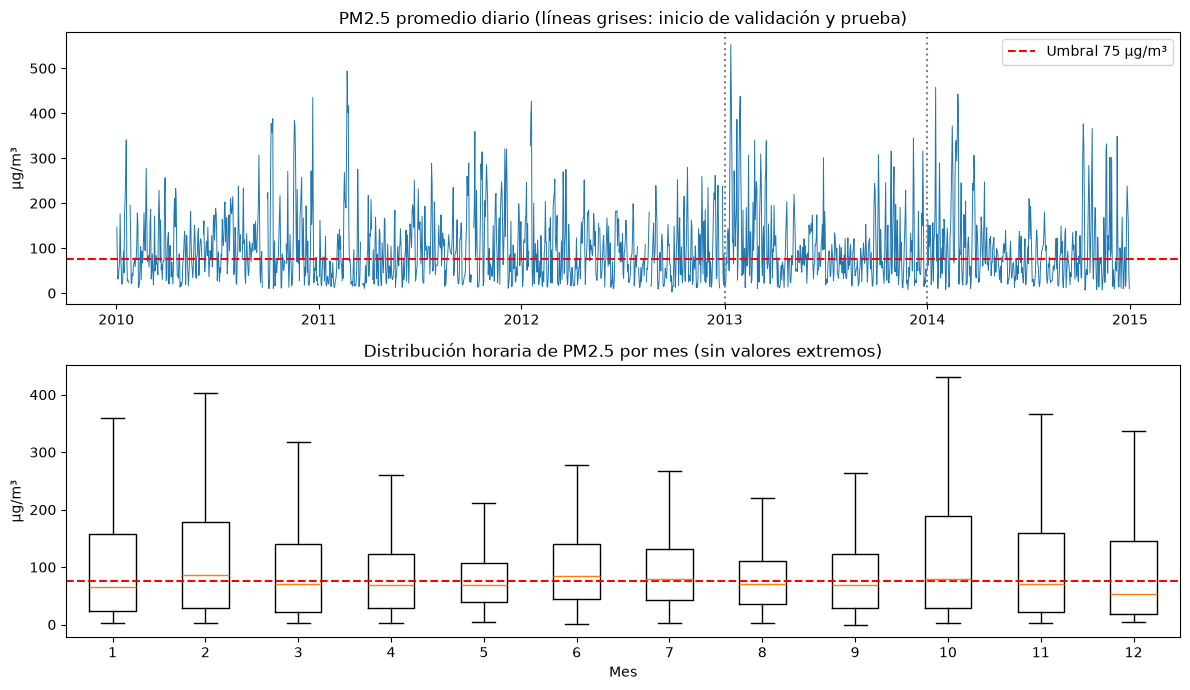

In [2]:
run("audit_data.py")
display(Image(REPORTS / "audit_pm25.png"))

- **Observación:** 43,824 horas continuas (2010-01-01 a 2014-12-31), sin horas faltantes ni duplicadas. Solo `pm2.5` tiene valores ausentes (2,067; 4.7 %), concentrados en 2010–2012.
- **Evidencia:** mediana de 72 µg/m³ y máximo de 994; el 48.5 % de las horas medidas supera 75 µg/m³. La proporción de horas *alto* es casi igual en entrenamiento, validación y prueba (≈ 48 %).
- **Interpretación:** clases equilibradas, pero con fuerte estacionalidad (inviernos más contaminados) y episodios que suben o bajan cientos de µg/m³ en pocas horas.
- **Decisión:** no imputar el objetivo; eliminar solo las horas sin PM2.5 actual o futuro. Imputar con la mediana (dentro del pipeline) los rezagos faltantes. Usar partición **temporal**, nunca aleatoria, porque horas vecinas son casi idénticas y una partición aleatoria filtraría información del futuro.

## 2. Entrenamiento, selección y evaluación

Entrenamiento 23871 · Validación 8605 · Prueba 8556


dummy: umbral=0.50 · F1 alto prueba=0.000 · recall=0.000
persistencia: umbral=0.50 · F1 alto prueba=0.691 · recall=0.691


logistica: umbral=0.50 · F1 alto prueba=0.728 · recall=0.776


gradient_boosting: umbral=0.45 · F1 alto prueba=0.755 · recall=0.847


   horizon_h  persistencia_f1_macro  gb_f1_macro  gb_roc_auc  mejora
0          6                  0.793        0.819       0.900   0.026
1         12                  0.702        0.733       0.808   0.031
2         24                  0.627        0.634       0.679   0.007
               model  threshold  valid_f1_alto  valid_recall_alto  valid_precision_alto  valid_f1_macro  valid_roc_auc  valid_pr_auc  f1_alto  recall_alto  precision_alto  f1_macro  roc_auc  pr_auc  fit_median_s  predict_ms    size_kb
0              dummy       0.50         0.0000             0.0000                0.0000          0.3428            NaN           NaN   0.0000       0.0000          0.0000    0.3417      NaN     NaN        0.0659      8.9334     4.1953
1       persistencia       0.50         0.6777             0.6778                0.6775          0.6910            NaN           NaN   0.6907       0.6908          0.6906    0.7021      NaN     NaN        0.0000      0.1097     0.3516
2          logistic

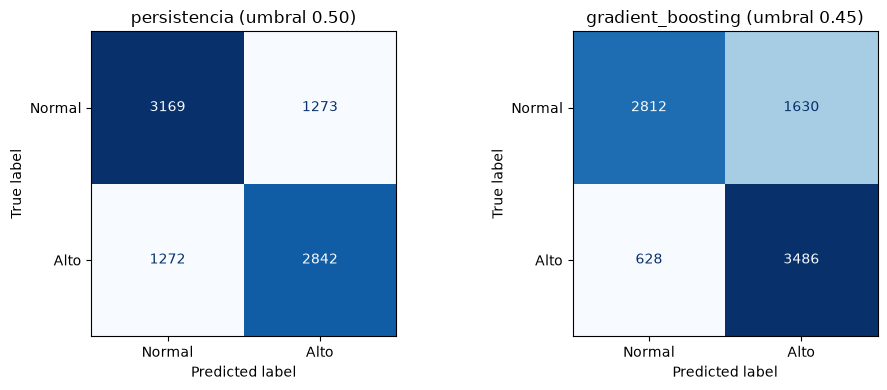

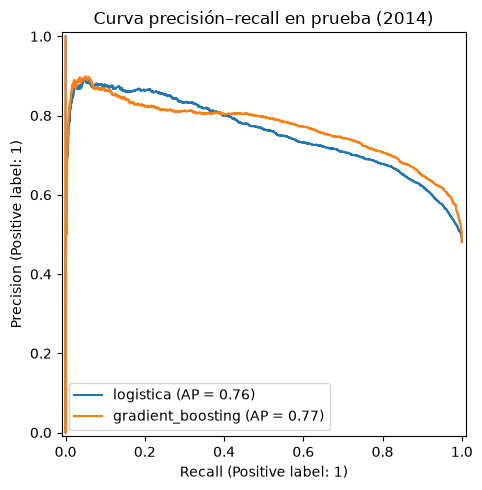

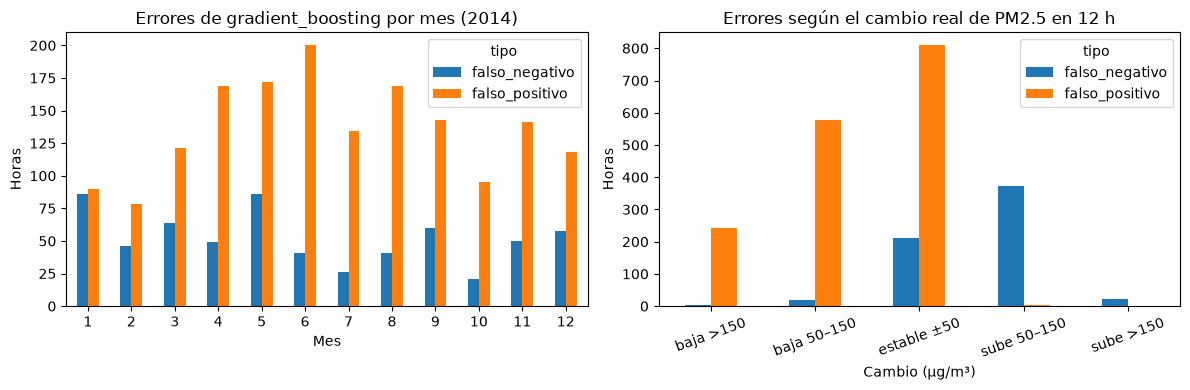

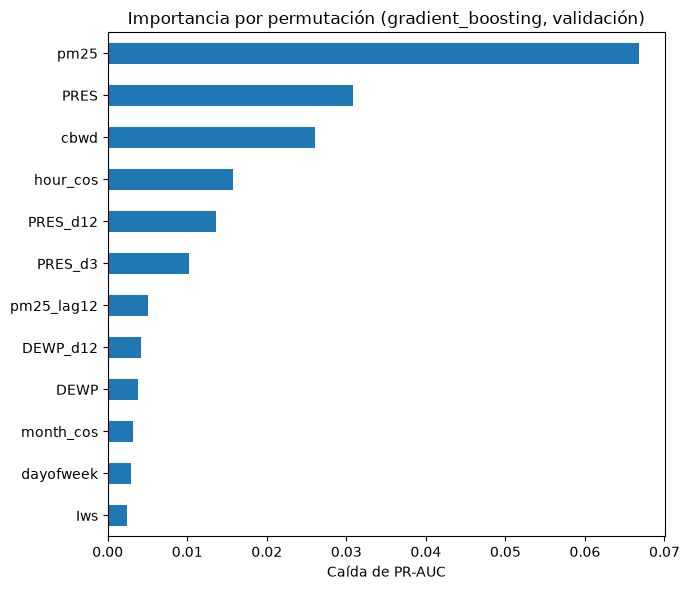

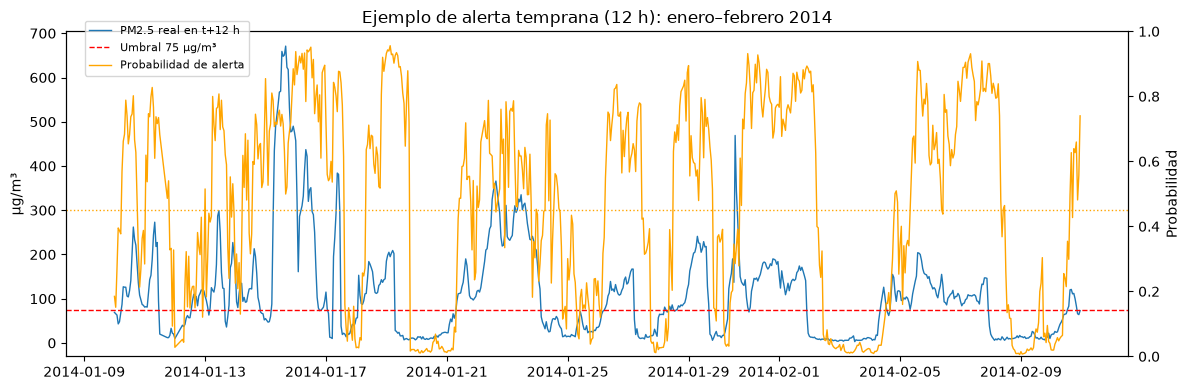

In [3]:
run("train.py")

In [4]:
metrics = pd.read_csv(REPORTS / "metrics.csv")
cols = ["model", "threshold", "valid_f1_macro", "f1_macro", "recall_alto", "precision_alto", "roc_auc",
        "fit_median_s", "predict_ms", "size_kb"]
display(metrics[cols].round(3))
print(json.loads((REPORTS / "summary.json").read_text()))

,model,threshold,valid_f1_macro,f1_macro,recall_alto,precision_alto,roc_auc,fit_median_s,predict_ms,size_kb
0,dummy,0.50,0.343,0.342,0.000,0.000,NaN,0.066,8.933,4.195
1,persistencia,0.50,0.691,0.702,0.691,0.691,NaN,0.000,0.110,0.352
2,logistica,0.50,0.707,0.722,0.776,0.687,0.793,0.132,9.647,5.781
3,gradient_boosting,0.45,0.720,0.734,0.847,0.681,0.819,5.584,67.925,1090.531


{'selected_model': 'gradient_boosting', 'threshold': 0.45, 'horizon_hours': 12, 'rows': {'train': 23871, 'valid': 8605, 'test': 8556}, 'test_high_rate': 0.48083216456287986, 'environment': {'python': '3.12.16', 'platform': 'Windows-11-10.0.26300-SP0', 'processor': 'Intel64 Family 6 Model 186 Stepping 3, GenuineIntel', 'scikit_learn': '1.9.1'}}


- **Baselines:** `dummy` (siempre la clase mayoritaria) y **persistencia** (“dentro de 12 h el nivel será el de ahora”), que es la referencia exigente: ya acierta la mayoría de las horas porque el PM2.5 cambia lentamente.
- **Modelos candidatos:** regresión logística y *gradient boosting* (HistGradientBoosting), ambos con `class_weight="balanced"` y el mismo preprocesamiento dentro de un `Pipeline`.
- **Selección:** el umbral de probabilidad y el modelo se eligen con **validación (2013)** maximizando F1 macro; luego el modelo se reentrena con 2010–2013 y se evalúa una sola vez en 2014.
- **Resultado:** gradient boosting es el mejor en validación y en prueba (F1 macro ≈ 0.75 frente a ≈ 0.70 de persistencia), y detecta más horas de contaminación alta (recall ≈ 0.82 frente a ≈ 0.69).

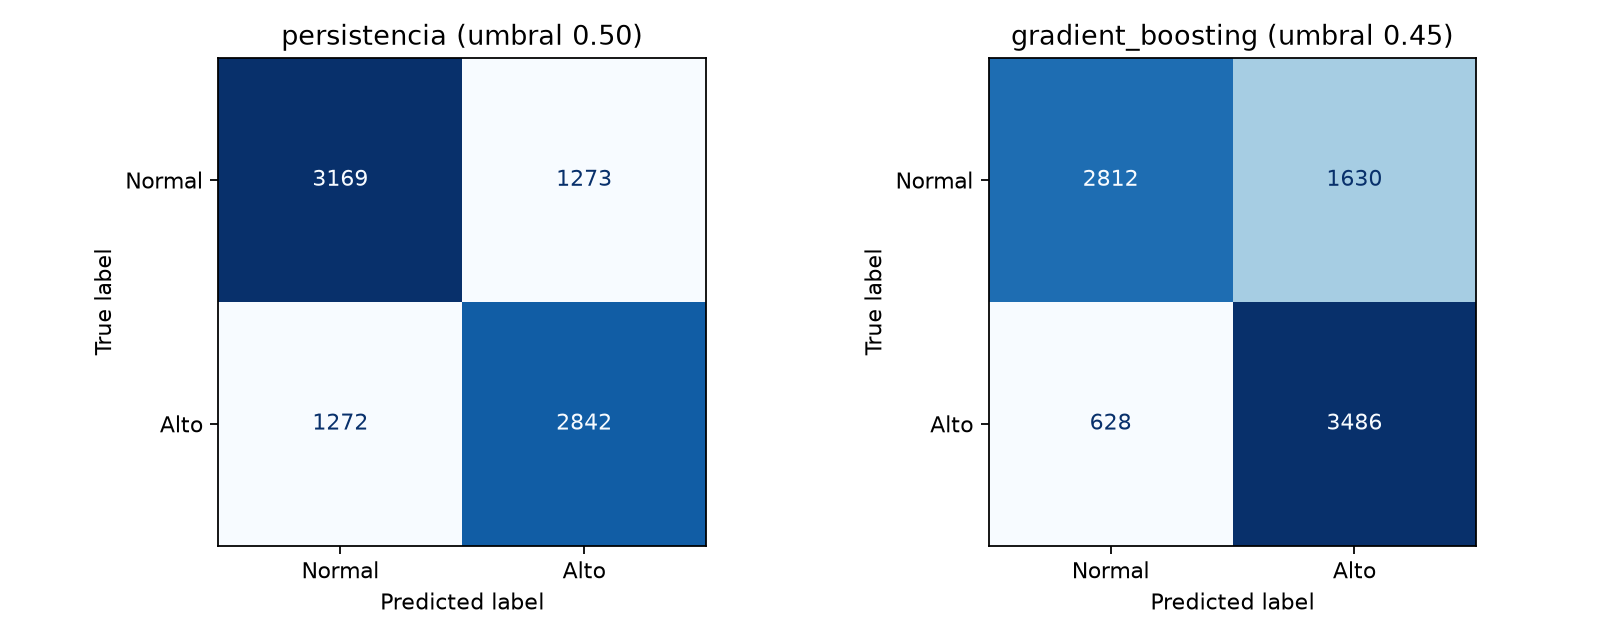

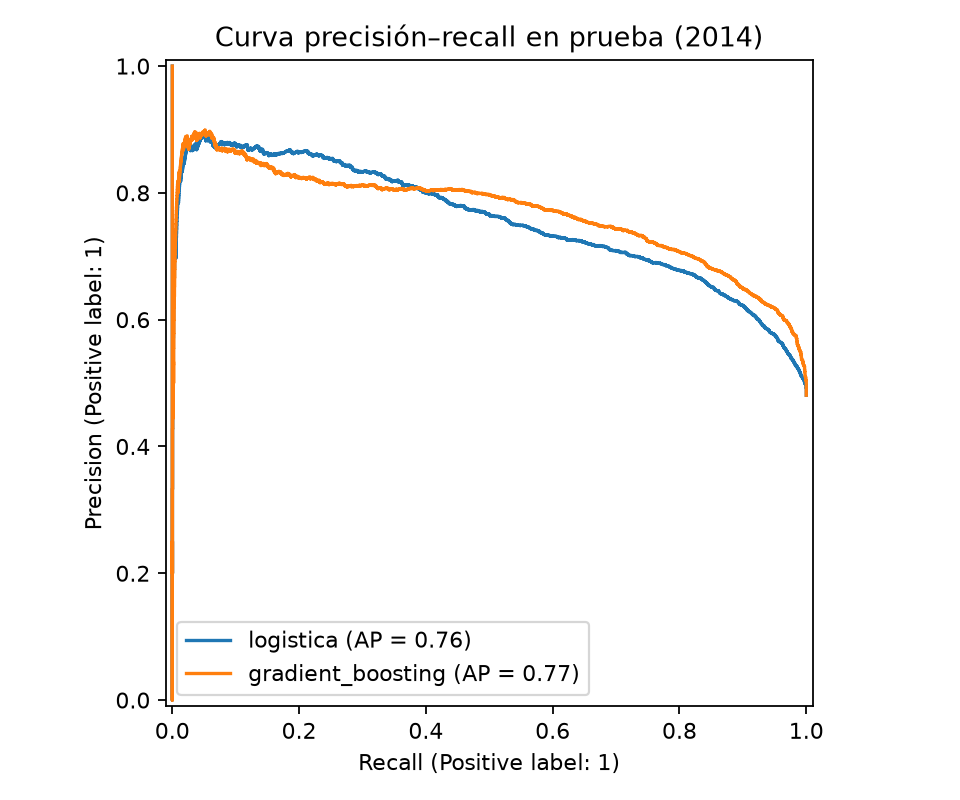

In [5]:
display(Image(REPORTS / "confusion_test.png"))
display(Image(REPORTS / "pr_curve.png"))

## 3. ¿Cuánto se puede anticipar? Comparación de horizontes

In [6]:
pd.read_csv(REPORTS / "horizon_comparison.csv")

,horizon_h,persistencia_f1_macro,gb_f1_macro,gb_roc_auc,mejora
0,6,0.7931,0.8189,0.8999,0.0258
1,12,0.7021,0.7332,0.8077,0.0311
2,24,0.6269,0.6341,0.6792,0.0072


Con 6 horas el problema es más fácil, pero la persistencia ya es muy buena. Con 24 horas el modelo casi no supera a la persistencia (la meteorología de mañana no está en los datos de hoy). **12 horas** es el horizonte donde la mejora sobre la persistencia es mayor y la alerta todavía da medio día de margen; por eso es el horizonte del proyecto.

## 4. Análisis de errores

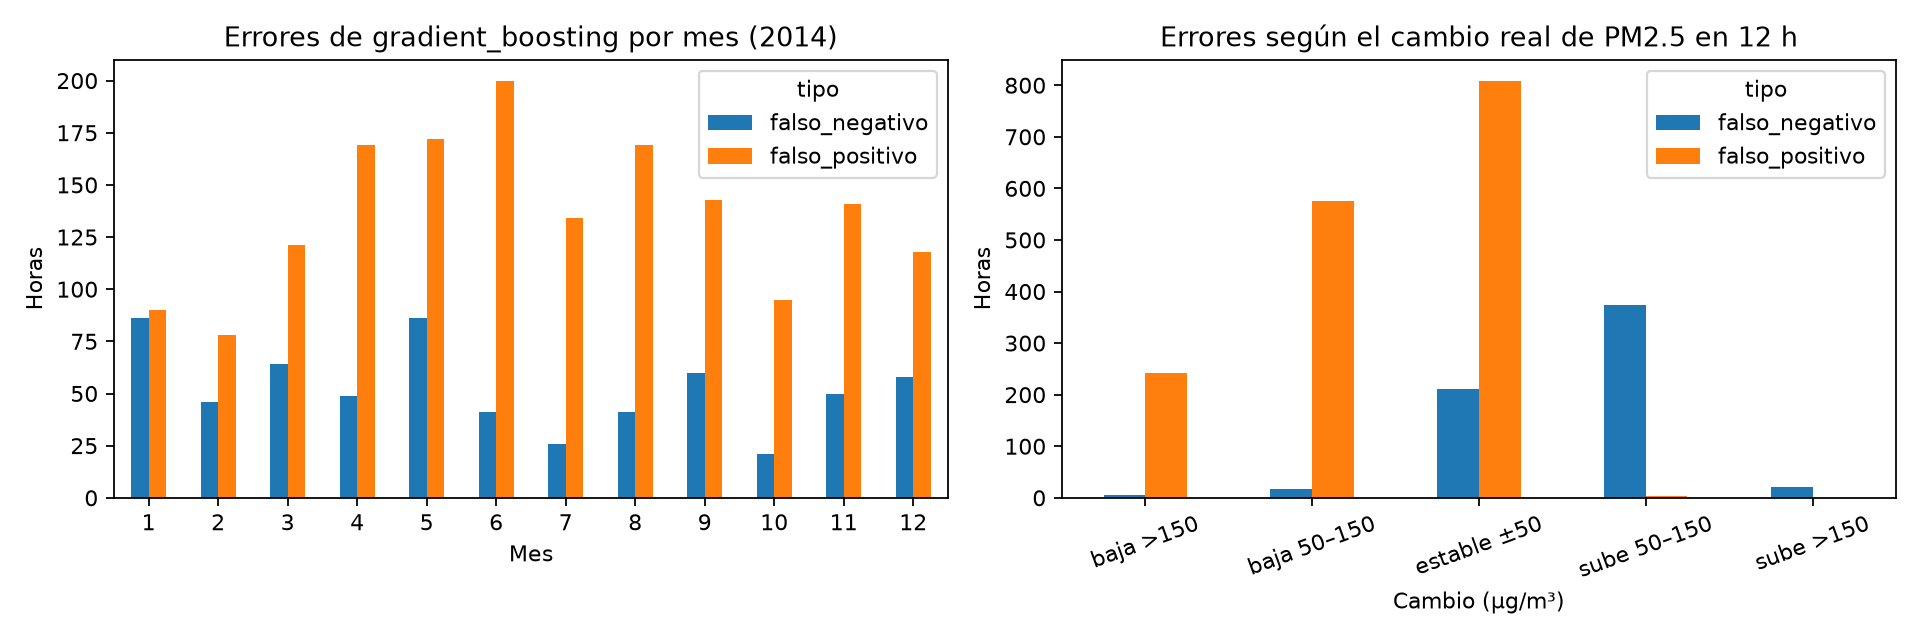

,cambio,acierto,falso_negativo,falso_positivo
0,baja >150,136,5,242
1,baja 50–150,554,18,576
2,estable ±50,4339,211,809
3,sube 50–150,1103,373,3
4,sube >150,166,21,0


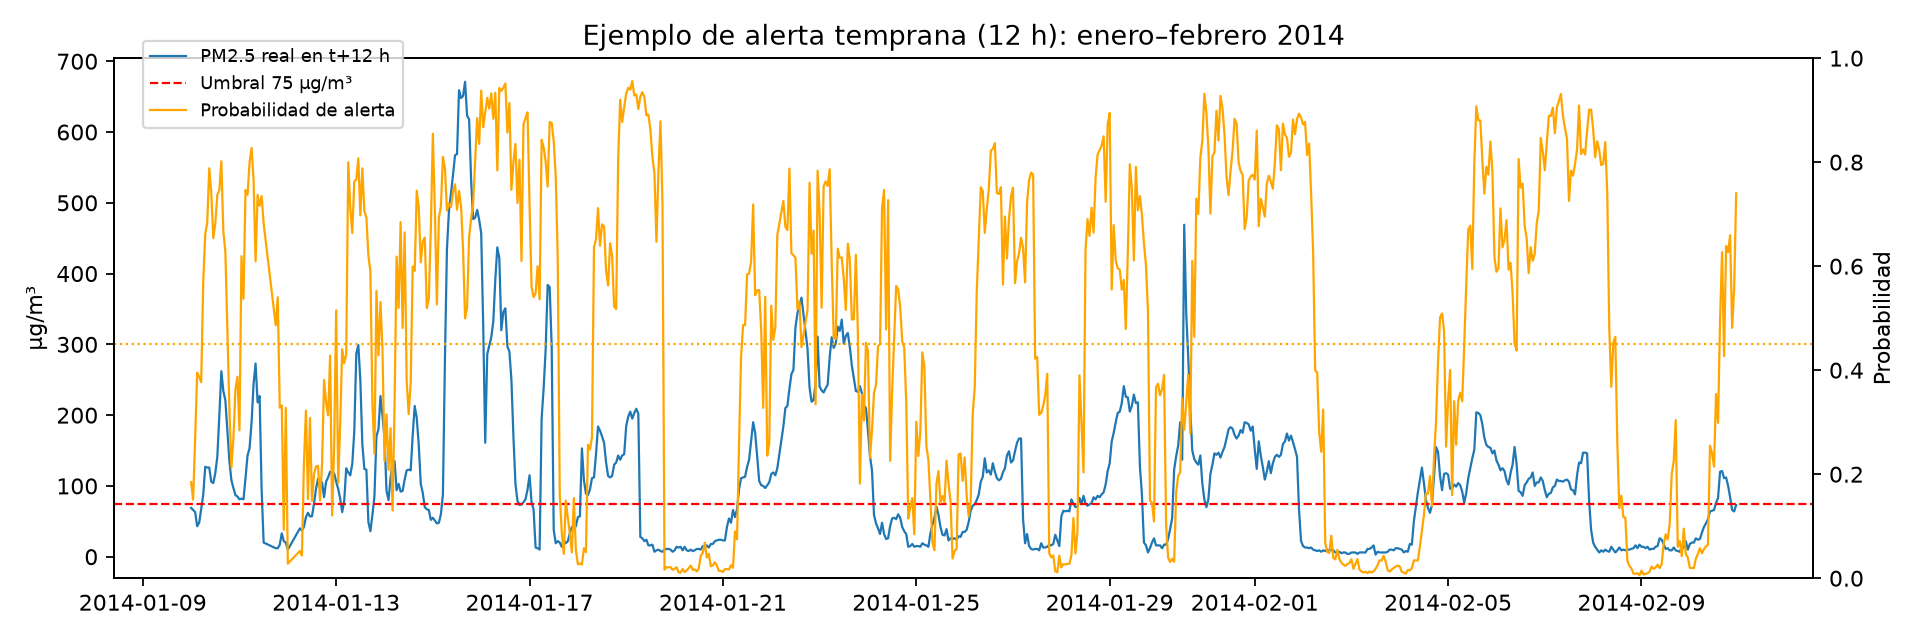

In [7]:
display(Image(REPORTS / "errors_analysis.png"))
display(pd.read_csv(REPORTS / "errors_by_change.csv"))
display(Image(REPORTS / "timeline_example.png"))

- **Falsos negativos** (alerta que no se dio): se concentran en horas donde el PM2.5 **sube entre 50 y 150 µg/m³** en las 12 horas siguientes. El modelo reacciona tarde al inicio de un episodio, cuando el aire todavía está limpio.
- **Falsos positivos** (alerta innecesaria): ocurren sobre todo cuando el PM2.5 **baja** o se mantiene cerca del umbral; típicamente, un frente de viento del noroeste limpia el aire más rápido de lo previsto.
- **Por mes:** los falsos positivos son más frecuentes de abril a agosto y los falsos negativos en enero y mayo.
- **Hipótesis:** incluir pronóstico meteorológico (viento y presión futuros) reduciría ambos tipos de error.

## 5. Variables más influyentes

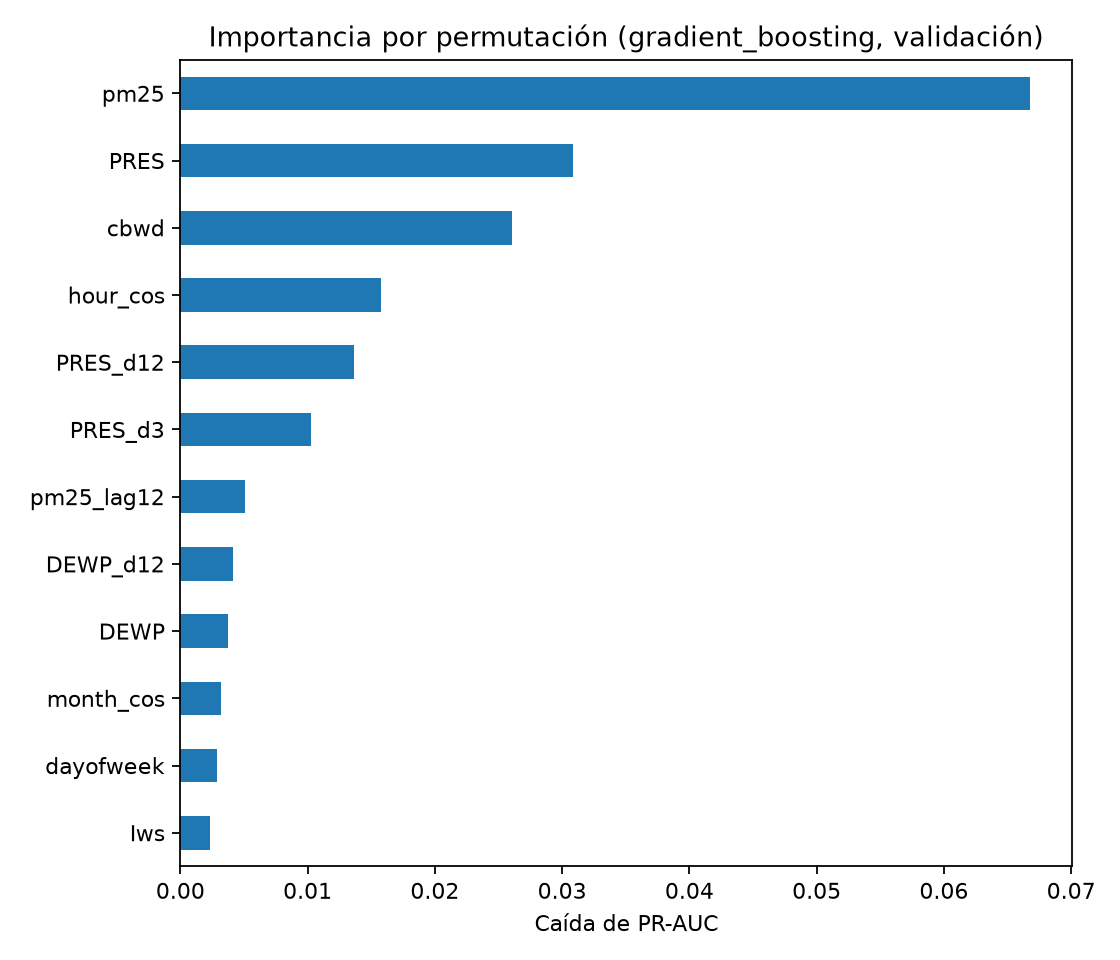

In [8]:
display(Image(REPORTS / "feature_importance.png"))

El PM2.5 actual es la variable más importante, seguida de la **presión**, la **dirección del viento** y la **tendencia de la presión** (cambio en 3 y 12 horas). Esto es coherente con la meteorología: la caída de presión y el viento del noroeste suelen anticipar la limpieza del aire. La importancia por permutación muestra asociación, no causalidad.

## 6. Verificaciones

In [9]:
import joblib
from calidad_aire.config import MODELS
from calidad_aire.data import load_raw
from calidad_aire.features import modeling_table, temporal_split, xy
bundle = joblib.load(MODELS / "selected_model.joblib")
_, _, test = temporal_split(modeling_table(load_raw()))
X, y = xy(test.iloc[:5])
proba = bundle["model"].predict_proba(X)[:, 1]
assert ((proba >= 0) & (proba <= 1)).all()
print(bundle["name"], "umbral", bundle["threshold"], "| probabilidades:", proba.round(3), "| reales:", y.tolist())

gradient_boosting umbral 0.45 | probabilidades: [0.052 0.111 0.078 0.102 0.39 ] | reales: [0, 0, 0, 0, 0]


## Conclusión
El modelo de gradient boosting anticipa con 12 horas las horas de PM2.5 alto mejor que la persistencia, sobre todo porque detecta más episodios. Su costo es mayor que el de la regresión logística (más tiempo de ajuste y un archivo de ≈ 1 MB frente a ≈ 6 KB), pero sigue siendo bajo en términos absolutos. Los errores principales están en los cambios bruscos de nivel, que dependen de la meteorología futura. El tablero (`app/streamlit_app.py`) permite explorar escenarios y el historial de 2014.